# 08 · Stage 3: LTspice simulation of the bench staircase

**Purpose.** Simulates the configuration-A bench experiment step for step in LTspice: the feedback resistor follows the Arduino's 32-tap staircase exactly, after the same trigger pulse, at any list of sweep rates, and every run is saved in the same three-column format as an oscilloscope file. This lets the bench analysis (notebook 05) run unchanged on simulated data, at rates far beyond what the bench could reach.

**In the report.** Chapter 6, Sec. 6.1 (43 rates from 52 Ω/s to 103 kΩ/s); Chapter 3, Sec. 3.6. The saved runs are analysed in notebook 09.

## Theory and protocol

Circuit: Wien bridge with $R = 2.17\,\mathrm{k\Omega}$, $C = 1\,\mu\mathrm{F}$, LM741 on ±15 V, $R_i = 47\,\mathrm{k\Omega}$, and $R_F$ a behavioural resistor `R = 1k*V(rctl)`: the control voltage in volts equals $R_F$ in kΩ. With identical arms the threshold is $G_c = 3$, i.e. $R_F = 94\,\mathrm{k\Omega}$. A random voltage `0.001*white(5e2*time + nseed)` in series with $R_i$ seeds the oscillation; `nseed` differs between runs.

Timeline of every run (identical to `Rf_sweep_staircase.ino`, see notebook 03): 2 s at tap 0, a 50 ms trigger pulse, then increments at $t_0 + j\tau$ and decrements at $t_0 + (32 + j)\tau$, period $64\tau$, with $\tau = 312.5\,\Omega/\lambda_{\rm nominal}$ (the sketch's convention). Each pot step is a 10 µs linear transition in the piecewise-linear (PWL) control source.

## Method

1. **Staircase** (pure Python): list every tap change exactly as the Arduino loop makes it, clamped at taps 0 and 31, and write it as a PWL file for the control source `Vr`.
2. **Netlist**: LTspice converts the schematic to a netlist once; for each run `PyLTSpice` sets `Vr` to the PWL file and the parameters `Tstop`, `maxstep` (0.1 ms, about 136 points per oscillation period) and `nseed`.
3. **Run** LTspice. If a run fails, it is retried once with `.options method=gear cshunt=1e-15` (the LM741 model is kept).
4. **Read** the binary `.raw` file with a small built-in reader (time as float64, traces as float32), and check that $R_F$ really followed `V(rctl)`: $(V_{\rm inv} - V_{\rm out})/I_{R1}$ against $1000\,V_{\rm rctl}$.
5. **Save** `TIME, CH2 - Trigger, CH1 - Vout, Rf_kohm` on a uniform 0.25 ms grid as `simdata - <rate>ohms.csv.gz`, and log every run (rate, step time, method, status, wall time) in `sim_runlog.csv`.

Five sweep cycles are simulated per rate; from 15 kΩ/s on, 15 cycles, because the oscillation needs several sweeps to build up from noise and those warm-up cycles are skipped by the analysis.

## Requirements

- LTspice 24 or later and `PyLTSpice` (with `spicelib`) for the simulation cells; the TI LM741 model `lm741.lib` (product page of the LM741, "PSpice model", archive `snom211b`) next to the schematic.
- `numpy`, `pandas`, `matplotlib` for everything else. With `RUN_SIMULATION = False` (default) only the staircase is built and the included sample run is checked.

## Inputs (the only cell to edit)

In [1]:
# ---------------- INPUTS ----------------
RUN_SIMULATION = False             # True -> run LTspice for every rate in LAMBDAS (can take hours)
LTSPICE_EXE = r"C:\Program Files\LTspice.exe"
SCHEMATIC   = "../ltspice/stage3_staircase/wien_bridge_staircase.asc"   # R_F = 1k*V(rctl); Vr placeholder PWL(0 91)
OUT_FOLDER  = "outputs/08_stage3/sim_data"     # simulated CSVs, PWL files, run log
WORK_FOLDER = "outputs/08_stage3/sim_work"     # LTspice netlists / raw / log files

LAMBDAS = [50, 75, 100, 150, 200, 250, 300, 350, 400, 450, 500, 750, 1000, 2000, 3000, 3500,
           3700, 3800, 3850, 3900, 3950, 3975, 4000, 5000, 6000, 7500, 9000, 10000,
           12000, 15000, 18000, 20000, 25000, 30000, 35000, 40000, 45000, 50000, 60000, 70000,
           80000, 90000, 100000]    # nominal rates, ohm/s (the 43 rates of the report)

N_CYCLES = 5; HIGH_RATE_LAMBDA = 15000; N_CYCLES_HIGH_RATE = 15
R0 = 91e3; DELTA_R = 10e3; N_STEPS = 31; STEPS_PER_HALF = 32
STEP_R_NOMINAL = 312.5       # ohm; the sketch's delay = 312.5 ohm / lambda
T_SETTLE = 2.0; TRIG_WIDTH = 0.05; TRIG_EDGE = 1e-6; STEP_EDGE = 10e-6
TAIL_FRACTION = 0.6          # extra fraction of a cycle simulated after the last full cycle
MAXSTEP = 1e-4; DT_OUT = 0.25e-3
NOISE_SEED_STEP = 1000.0; SIM_TIMEOUT = 48 * 3600
RETRY_WITH_GEAR = True; STOP_ON_FAILURE = True; SKIP_EXISTING = True; KEEP_RAW = False; VERIFY_RF = True

SAMPLE_RATE = 1000                                   # the included sample run, for the offline checks
SAMPLE_PWL  = "../data/stage3/rctl_lam1000.pwl"
SAMPLE_CSV  = "../data/stage3/simdata - 1000ohms.csv.gz"

## 1. The staircase (pure Python, no LTspice needed)

In [2]:
import os, time, datetime
import numpy as np, pandas as pd, matplotlib.pyplot as plt
OUT_FOLDER, WORK_FOLDER = os.path.abspath(OUT_FOLDER), os.path.abspath(WORK_FOLDER)
RUN_LOG = os.path.join(OUT_FOLDER, 'sim_runlog.csv'); RUN_LOG_DIR = os.path.join(OUT_FOLDER, 'runlog')
os.makedirs(OUT_FOLDER, exist_ok=True)
STEP_R = DELTA_R / N_STEPS
TOP_TAP = min(STEPS_PER_HALF, N_STEPS)

def lam_tag(lam):
    return f"{lam:g}"


def n_cycles_for(lam):
    return N_CYCLES_HIGH_RATE if lam >= HIGH_RATE_LAMBDA else N_CYCLES


def sweep_timing(lam):
    tau = STEP_R_NOMINAL / lam                       # s per step (Arduino delay)
    t0 = T_SETTLE + TRIG_WIDTH + TRIG_EDGE           # end of the trigger's falling edge
    T = 2 * STEPS_PER_HALF * tau
    t_stop = t0 + (n_cycles_for(lam) + TAIL_FRACTION) * T
    return tau, t0, T, t_stop


def staircase_events(lam):
    """(time, tap_after) for every pot step, exactly as the Arduino loop does it."""
    tau, t0, T, t_stop = sweep_timing(lam)
    tap, events = 0, []
    for c in range(n_cycles_for(lam) + 1):           # one extra cycle covers the tail
        if t0 + 2 * STEPS_PER_HALF * c * tau > t_stop:
            break
        for j in range(STEPS_PER_HALF):              # increments
            t_e = t0 + (2 * STEPS_PER_HALF * c + j) * tau
            new = min(tap + 1, TOP_TAP)
            if new != tap:
                events.append((t_e, tap, new)); tap = new
        for j in range(STEPS_PER_HALF):              # decrements
            t_e = t0 + (2 * STEPS_PER_HALF * c + STEPS_PER_HALF + j) * tau
            new = max(tap - 1, 0)
            if new != tap:
                events.append((t_e, tap, new)); tap = new
    return events


def write_pwl(lam, path):
    """PWL for V(rctl) in volts = kohm: flat between steps, STEP_EDGE-long linear transitions."""
    tau, t0, T, t_stop = sweep_timing(lam)
    kohm = lambda tap: (R0 + STEP_R * tap) / 1e3
    pts = [(0.0, kohm(0))]
    for t_e, old, new in staircase_events(lam):
        if t_e > t_stop:                                 # steps after the end of the simulation are not needed
            break
        pts.append((t_e, kohm(old)))
        pts.append((t_e + STEP_EDGE, kohm(new)))
    pts.append((max(pts[-1][0], t_stop) + 1.0, pts[-1][1]))
    times = np.array([p[0] for p in pts])
    if not np.all(np.diff(times) > 0):                   # LTspice rejects non-increasing PWL times
        raise ValueError(f"PWL times not strictly increasing for lambda = {lam}")
    with open(path, "w") as fh:
        for t, val in pts:
            fh.write(f"{t:.9f} {val:.9f}\n")
    return len(pts)

## 2. LTspice helpers: netlist, run, raw-file reader, checks

In [3]:
BASE_NETLIST = None


def make_base_netlist():
    """Convert the schematic to a netlist ONCE (LTspice -netlist). Calling it before every run is slow and
    can hang if LTspice opens a dialog."""
    global BASE_NETLIST
    SpiceEditor(os.path.abspath(SCHEMATIC))               # writes <schematic>.net next to the .asc
    BASE_NETLIST = os.path.splitext(os.path.abspath(SCHEMATIC))[0] + ".net"
    if not os.path.exists(BASE_NETLIST):
        raise FileNotFoundError(f"LTspice did not create {BASE_NETLIST}")
    print("Base netlist:", BASE_NETLIST)
    print(read_text(BASE_NETLIST))


def read_text(path):
    raw = open(path, "rb").read()
    for enc in ("utf-8", "utf-16", "latin-1"):
        try:
            txt = raw.decode(enc)
            if "\x00" not in txt:
                return txt
        except UnicodeDecodeError:
            pass
    return raw.decode("latin-1", errors="replace")


def show_failure(stem):
    """Print what LTspice said (log/fail file) and the netlist it was given."""
    for ext in (".log", ".fail"):
        p = os.path.join(WORK_FOLDER, stem + ext)
        if os.path.exists(p):
            txt = read_text(p).strip().splitlines()
            print(f"   ---- {os.path.basename(p)} (last 25 lines) ----")
            for line in txt[-25:]:
                print("   " + line)
    p = os.path.join(WORK_FOLDER, stem + ".net")
    if os.path.exists(p):
        print(f"   ---- {os.path.basename(p)} ----")
        for line in read_text(p).splitlines():
            print("   " + line)
    else:
        print(f"   (no netlist {p} - LTspice was not even given a file)")


def run_ltspice(lam, idx, pwl_path, gear=False):
    tau, t0, T, t_stop = sweep_timing(lam)
    stem = f"sim_lam{lam_tag(lam)}" + ("_gear" if gear else "")
    editor = SpiceEditor(BASE_NETLIST)
    pwl_value = f'PWL file="{os.path.abspath(pwl_path)}"'
    editor.set_component_value("Vr", pwl_value)          # schematic placeholder is PWL(0 91)
    now = str(editor.get_component_value("Vr"))
    if now.count("file=") != 1 or os.path.abspath(pwl_path) not in now:
        raise RuntimeError(f"Vr value not replaced cleanly: {now!r}. Vr's value in the schematic must be PWL(0 91).")
    editor.set_parameters(Tstop=f"{t_stop:.9g}", maxstep=f"{MAXSTEP:.9g}", nseed=f"{idx * NOISE_SEED_STEP:g}")
    if gear:
        editor.add_instruction(".options method=gear cshunt=1e-15")
    try:
        runner = SimRunner(output_folder=WORK_FOLDER, timeout=SIM_TIMEOUT)
    except TypeError:                                   # older PyLTSpice without the timeout keyword
        runner = SimRunner(output_folder=WORK_FOLDER)
    try:
        runner.run(editor, run_filename=f"{stem}.net", timeout=SIM_TIMEOUT)
    except TypeError:
        runner.run(editor)
    runner.wait_completion()
    raw_path = os.path.join(WORK_FOLDER, f"{stem}.raw")      # transient data (NOT the *_op.raw file)
    log_path = os.path.join(WORK_FOLDER, f"{stem}.log")
    if not os.path.exists(raw_path):
        present = sorted(f for f in os.listdir(WORK_FOLDER) if f.startswith(stem))
        print(f"   {os.path.basename(raw_path)} not found. Files for this run in sim_work: {present}")
    return raw_path, log_path, stem


def read_ltspice_raw(path):
    """Minimal reader for an LTspice binary .raw file (transient analysis, real data).
    Layout (LTspice 24): UTF-16-LE header ending in 'Binary:\\n', then per point: the first variable
    (time) as float64 and every other variable as float32 ('double' flag: all float64).
    The number of points is taken from the file size, so a partly written file is still readable."""
    size = os.path.getsize(path)
    with open(path, "rb") as fh:
        head = fh.read(min(size, 1 << 20))
    for enc, marker in (("utf-16-le", "Binary:\n".encode("utf-16-le")), ("latin-1", b"Binary:\n")):
        pos = head.find(marker)
        if pos >= 0:
            header, offset = head[:pos].decode(enc, errors="replace"), pos + len(marker)
            break
    else:
        raise ValueError(f"{os.path.basename(path)}: no 'Binary:' section (ASCII raw files are not supported)")
    info, names, in_vars = {}, [], False
    for line in header.splitlines():
        if in_vars:
            parts = line.split()
            if len(parts) >= 2 and parts[0].isdigit():
                names.append(parts[1])
            continue
        if line.startswith("Variables:"):
            in_vars = True
        elif ":" in line:
            k, v = line.split(":", 1)
            info[k.strip()] = v.strip()
    plot, flags = info.get("Plotname", "?"), info.get("Flags", "").lower()
    if not names or names[0].lower() != "time":
        raise ValueError(f"{os.path.basename(path)}: plot '{plot}' has no time axis (variables: {names})")
    if "complex" in flags:
        raise ValueError(f"{os.path.basename(path)}: complex data not supported")
    nv = len(names)
    wt, wv = 8, (8 if "double" in flags else 4)              # bytes for time / for every other variable
    n = (size - offset) // (wt + (nv - 1) * wv)                # points actually present in the file
    cols = {}
    if "fastaccess" in flags:                                  # column-wise layout: all time values, then each trace
        n_hdr = int(info.get("No. Points", n))
        n = min(n, n_hdr) if n_hdr > 0 else n
        pos = offset
        for k, nm in enumerate(names):
            w = wt if k == 0 else wv
            col = np.fromfile(path, dtype="<f8" if w == 8 else "<f4", count=n, offset=pos)
            cols[nm] = col.astype(float)
            pos += w * n_hdr
    else:                                                      # point-wise layout (LTspice default)
        dtype = (np.dtype([("v", "<f8", (nv,))]) if wv == 8
                 else np.dtype([("t", "<f8"), ("v", "<f4", (nv - 1,))]))
        rec = np.memmap(path, dtype=dtype, mode="r", offset=offset, shape=(n,))
        if wv == 8:
            arr = np.array(rec["v"], dtype=float)              # copy: the file must not stay mapped
            cols = {nm: arr[:, k].copy() for k, nm in enumerate(names)}
        else:
            cols[names[0]] = np.array(rec["t"], dtype=float)
            v = np.array(rec["v"], dtype=float)
            for k, nm in enumerate(names[1:]):
                cols[nm] = v[:, k].copy()
        del rec                                                # release the file (Windows can then delete it)
    return {k.lower(): val for k, val in cols.items()}, f"{plot} [{flags}]", n


def read_and_check(raw_path, t_stop):
    """Returns (data, status, ltspice_ok). ltspice_ok = False means LTspice itself did not finish
    (worth a retry with gear); True with data None means the run finished but the output is unusable."""
    if not os.path.exists(raw_path):
        return None, "no transient raw file", False
    cols, plot, n = read_ltspice_raw(raw_path)
    t = np.abs(cols["time"])
    print(f"   raw file: {os.path.basename(raw_path)} | plot '{plot}' | {n} points | "
          f"{os.path.getsize(raw_path)/1e6:.0f} MB | traces {list(cols)}")
    if t[-1] < 0.999 * t_stop:
        return None, f"stopped early at t = {t[-1]:.4f} s of {t_stop:.4f} s", False
    missing = [k for k in ("v(vout)", "v(trig)", "v(rctl)") if k not in cols]
    if missing:
        return None, f"traces missing in raw file: {missing}", True
    data = dict(t=t, vout=cols["v(vout)"], trig=cols["v(trig)"], rctl=cols["v(rctl)"])
    if VERIFY_RF and "v(inv)" in cols and "i(r1)" in cols:
        ok = np.abs(cols["i(r1)"]) > 1e-6
        if ok.sum() > 100:
            r_eff = np.abs((cols["v(inv)"][ok] - data["vout"][ok]) / cols["i(r1)"][ok])
            data["rf_check"] = np.median(np.abs(r_eff / (1e3 * data["rctl"][ok]) - 1))
    return data, "ok", True


def cleanup(stem):
    for ext in (".raw", ".log", ".net", "_op.raw", ".fail"):
        p = os.path.join(WORK_FOLDER, stem + ext)
        if os.path.exists(p):
            os.remove(p)


def to_uniform_csv(data, t_stop, csv_path):
    """Resample LTspice's variable time steps onto a uniform DT_OUT grid (the analysis rebuilds time
    from the sample index, exactly as for the DSO files) and save as gzipped CSV."""
    t, keep = np.unique(data["t"], return_index=True)
    grid = np.arange(0.0, t_stop + 0.5 * DT_OUT, DT_OUT)
    out = pd.DataFrame({
        "TIME": grid,
        "CH2 - Trigger": np.interp(grid, t, data["trig"][keep]),
        "CH1 - Vout": np.interp(grid, t, data["vout"][keep]),
        "Rf_kohm": np.interp(grid, t, data["rctl"][keep]),
    })
    out.to_csv(csv_path, index=False, float_format="%.6f", compression="gzip")
    return len(out)


def log_run(row):
    """One log file per lambda (safe for parallel notebooks), then rebuild the combined RUN_LOG."""
    os.makedirs(RUN_LOG_DIR, exist_ok=True)
    pd.DataFrame([row]).to_csv(os.path.join(RUN_LOG_DIR, f"lam{lam_tag(row['lambda_nominal'])}.csv"), index=False)
    parts = [pd.read_csv(os.path.join(RUN_LOG_DIR, f)) for f in sorted(os.listdir(RUN_LOG_DIR)) if f.endswith(".csv")]
    pd.concat(parts, ignore_index=True).sort_values("lambda_nominal").to_csv(RUN_LOG, index=False)

## 3. Batch runner

In [4]:
def run_all():
    os.makedirs(OUT_FOLDER, exist_ok=True)
    os.makedirs(WORK_FOLDER, exist_ok=True)
    LTspice.create_from(LTSPICE_EXE)
    make_base_netlist()
    total_sim = sum(sweep_timing(l)[3] for l in LAMBDAS)
    print(f"{len(LAMBDAS)} runs, {total_sim:.0f} s of circuit time in total "
          f"(slowest: lambda = {min(LAMBDAS)} -> {sweep_timing(min(LAMBDAS))[3]:.0f} s).")

    speed = None                                          # wall seconds per simulated second (measured)
    for idx, lam in enumerate(LAMBDAS):
        tau, t0, T, t_stop = sweep_timing(lam)
        csv_path = os.path.join(OUT_FOLDER, f"simdata - {lam_tag(lam)}ohms.csv.gz")
        pwl_path = os.path.join(OUT_FOLDER, f"rctl_lam{lam_tag(lam)}.pwl")
        print("\n" + "#" * 90 + f"\nlambda = {lam} ohm/s | tau = {tau*1e3:.3f} ms | T = {T:.3f} s | "
              f"t0 = {t0:.6f} s | Tstop = {t_stop:.3f} s")
        if SKIP_EXISTING and os.path.exists(csv_path):
            print(f"   {csv_path} exists - skipped (set SKIP_EXISTING = False to redo).")
            continue
        n_pwl = write_pwl(lam, pwl_path)

        attempts = [False] + ([True] if RETRY_WITH_GEAR else [])
        status, data, method, wall = "not run", None, "", 0.0
        for gear in attempts:
            method = "gear+cshunt" if gear else "trap (default)"
            t_start = time.time()
            stem, ltspice_ok = f"sim_lam{lam_tag(lam)}" + ("_gear" if gear else ""), False
            try:
                raw_path, log_path, stem = run_ltspice(lam, idx, pwl_path, gear=gear)
                data, status, ltspice_ok = read_and_check(raw_path, t_stop)
            except Exception as err:
                data, status = None, f"error: {type(err).__name__}: {err}"
                ltspice_ok = os.path.exists(os.path.join(WORK_FOLDER, stem + ".raw"))
            wall = time.time() - t_start
            print(f"   [{method}] {status}  ({wall/60:.1f} min)")
            if data is not None:
                break
            show_failure(stem)                            # failed: keep the files and show why
            if ltspice_ok:
                print("   LTspice finished, but its output could not be used -> no gear retry.")
                break

        row = dict(lambda_nominal=lam, step_delay_ms=tau * 1e3, tau_s=tau, T_s=T, t0_s=t0, t_stop_s=t_stop,
                   n_cycles=n_cycles_for(lam), R0=R0, DELTA_R=DELTA_R, N_STEPS=N_STEPS, STEPS_PER_HALF=STEPS_PER_HALF,
                   maxstep_s=MAXSTEP, dt_out_s=DT_OUT, nseed=idx * NOISE_SEED_STEP, method=method,
                   status=status, wall_time_min=wall / 60, pwl_points=n_pwl, csv="",
                   rf_check_median_rel_err=np.nan,
                   finished_at=datetime.datetime.now().isoformat(timespec="seconds"))
        if data is not None:
            if "rf_check" in data:
                row["rf_check_median_rel_err"] = data["rf_check"]
                msg = "OK" if data["rf_check"] < 0.01 else "WARNING: R1 does NOT follow V(rctl)!"
                print(f"   Rf check: median |R1/(1k*V(rctl)) - 1| = {data['rf_check']:.2e}  {msg}")
            n = to_uniform_csv(data, t_stop, csv_path)
            row["csv"] = csv_path
            print(f"   saved {csv_path}  ({n} rows, dt = {DT_OUT*1e3:g} ms)")
            if not KEEP_RAW:
                cleanup(stem)
        log_run(row)
        if data is None and STOP_ON_FAILURE:
            print("\nSTOPPED: this run failed (see the LTspice messages above). Fix the cause, then re-run;"
                  " finished lambdas are skipped automatically.")
            return
        if data is not None and wall > 0:
            speed = wall / t_stop
            left = sum(sweep_timing(l)[3] for l in LAMBDAS[idx + 1:]
                       if not (SKIP_EXISTING and os.path.exists(os.path.join(OUT_FOLDER, f"simdata - {lam_tag(l)}ohms.csv.gz"))))
            print(f"   speed: {speed:.2f} s of wall time per simulated second -> remaining runs need about "
                  f"{left * speed / 3600:.1f} h")

    print("\nAll done. Run log:", RUN_LOG)
    print(pd.read_csv(RUN_LOG)[["lambda_nominal", "status", "method", "wall_time_min", "csv"]].to_string(index=False))

## 4. Run (needs LTspice)

In [5]:
if RUN_SIMULATION:
    from PyLTSpice import SimRunner, SpiceEditor
    from spicelib.simulators.ltspice_simulator import LTspice
    run_all()
else:
    print("RUN_SIMULATION = False: no LTspice runs.")

RUN_SIMULATION = False: no LTspice runs.


## Check: the staircase and the sample run

PASS the staircase built here matches the PWL file of the report's 1000 ohm/s run point for point (655 points)
   (that run was simulated with a shorter tail after the fifth cycle: it ends at 107.05 s, this setting at 113.93 s)
sample run: 428201 rows, dt = 0.25 ms, R_F range 91.00-101.00 kOhm, rail 13.9 V


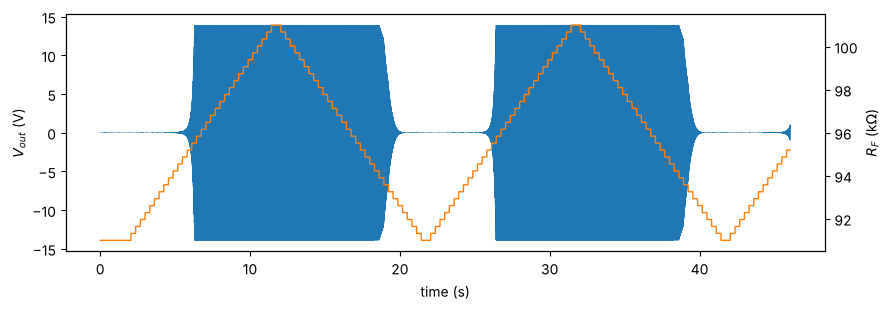

In [6]:
pwl_new = os.path.join(OUT_FOLDER, f"rctl_lam{SAMPLE_RATE}.pwl"); write_pwl(SAMPLE_RATE, pwl_new)
a, b = np.loadtxt(pwl_new), np.loadtxt(SAMPLE_PWL)
n = min(len(a), len(b)) - 1          # the last point only extends the final level to the end of the run
print(("PASS" if np.allclose(a[:n], b[:n], atol=1e-9) else "FAIL") +
      f" the staircase built here matches the PWL file of the report's {SAMPLE_RATE} ohm/s run point for point ({n} points)")
print(f"   (that run was simulated with a shorter tail after the fifth cycle: it ends at {b[-2,0]:.2f} s, this setting at {a[-2,0]:.2f} s)")
d = pd.read_csv(SAMPLE_CSV)
tau, t0, T, t_stop = sweep_timing(SAMPLE_RATE)
print(f"sample run: {len(d)} rows, dt = {d.TIME.diff().median()*1e3:.2f} ms, R_F range {d.Rf_kohm.min():.2f}-{d.Rf_kohm.max():.2f} kOhm, "
      f"rail {d['CH1 - Vout'].max():.1f} V")
fig, ax = plt.subplots(figsize=(9, 3.2)); s = d.TIME < t0 + 2.2 * T
ax.plot(d.TIME[s], d["CH1 - Vout"][s], lw=0.3); ax2 = ax.twinx(); ax2.plot(d.TIME[s], d.Rf_kohm[s], color="tab:orange", lw=1)
ax.set_xlabel("time (s)"); ax.set_ylabel(r"$V_{out}$ (V)"); ax2.set_ylabel(r"$R_F$ (k$\Omega$)"); fig.tight_layout(); plt.show()

## Using your own circuit

Edit the schematic (keep the node names `vout`, `trig`, `rctl`, `inv` and the sources `Vr`, `Vtrig`, `B1`), and change `R0`, `DELTA_R`, `N_STEPS` and `STEPS_PER_HALF` if your potentiometer or sketch differs. Analyse the saved runs with notebook 09 (or notebook 05 with `TAU_OVERRIDE_MS` set to the exact step time).